# A leaky integrate-and-fire classifier

Can a hard spike forward pass be trained with a surrogate derivative?

I implement membrane accumulation, thresholded spikes and detached resets in ordinary PyTorch. Input intensities are deterministic currents, making the experiment repeatable without random spike sampling.

## Run settings

The default run uses CPU and a small training budget. Set `PROJECT_FULL=1` before opening the notebook for the longer run. Both modes use the same data split and evaluation code. A short run checks the experiment; the number of epochs limits what its scores can establish.

In [3]:
import inspect
import json
import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import torch
from torch import nn

root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
if not (root / "pyproject.toml").exists():
    raise FileNotFoundError("Open this notebook inside the repository")
sys.path.insert(0, str(root / "src"))
from deep_projects.training import (
    Trainer,
    TrainConfig,
    classification_scores,
    digits_data,
    plot_history,
    predict,
    seed_everything,
)

QUICK = os.environ.get("PROJECT_FULL", "0") != "1"
EPOCHS = 6 if QUICK else 40
seed_everything(1031)
output = root / "figures" / "08_spiking_network"
output.mkdir(parents=True, exist_ok=True)
(root / "results").mkdir(exist_ok=True)
print({"torch": torch.__version__, "device": "cpu", "epochs": EPOCHS, "seed": 1031})

{'torch': '2.14.1+cu130', 'device': 'cpu', 'epochs': 40, 'seed': 1031}


## Membrane and spikes

At each step, membrane voltage follows $u_t=\lambda u_{t-1}+Wx$. A spike is emitted when $u_t>1$, then the detached spike subtracts the threshold from the state. The hard threshold has zero derivative almost everywhere, so the backward pass uses a specified smooth surrogate.

class SurrogateSpike(torch.autograd.Function):
    @staticmethod
    def forward(ctx, voltage):
        ctx.save_for_backward(voltage)
        return (voltage > 0).to(voltage.dtype)

    @staticmethod
    def backward(ctx, gradient):
        (voltage,) = ctx.saved_tensors
        return gradient / (1 + 5 * voltage.abs()).square()



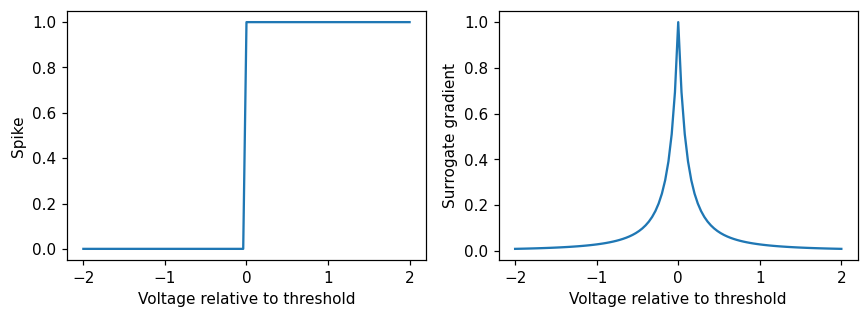

In [5]:
from deep_projects.models import SpikingMLP, SurrogateSpike

data = digits_data(8)
train_loader, validation_loader, test_loader = data.loaders()
print(inspect.getsource(SurrogateSpike))
voltage = torch.linspace(-2, 2, 101, requires_grad=True)
spikes = SurrogateSpike.apply(voltage)
spikes.sum().backward()
assert torch.isfinite(voltage.grad).all()
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].plot(voltage.detach(), spikes.detach())
axes[1].plot(voltage.detach(), voltage.grad)
axes[0].set(xlabel="Voltage relative to threshold", ylabel="Spike")
axes[1].set(xlabel="Voltage relative to threshold", ylabel="Surrogate gradient")
fig.tight_layout()
fig.savefig(output / "surrogate.png", dpi=140)
plt.show()

## Classification over simulation steps

The hidden layer spikes over twelve steps. A continuous linear readout averages spike-dependent outputs and supplies logits for cross-entropy. This is a hybrid spiking-hidden-layer model; its output layer is not a second spiking layer.

class SpikingMLP(nn.Module):
    def __init__(self, steps=12):
        super().__init__()
        self.input_layer = nn.Linear(64, 64)
        self.output_layer = nn.Linear(64, 10)
        self.steps = steps
        self.decay = 0.9

    def forward(self, images):
        intensities = images.flatten(1)
        membrane = intensities.new_zeros(len(images), 64)
        output = intensities.new_zeros(len(images), 10)
        for _ in range(self.steps):
            # Deterministic current encoding keeps evaluation repeatable.
            membrane = self.decay * membrane + self.input_layer(intensities)
            spikes = SurrogateSpike.apply(membrane - 1)
            membrane = membrane - spikes.detach()
            output = output + self.output_layer(spikes)
        return output / self.steps



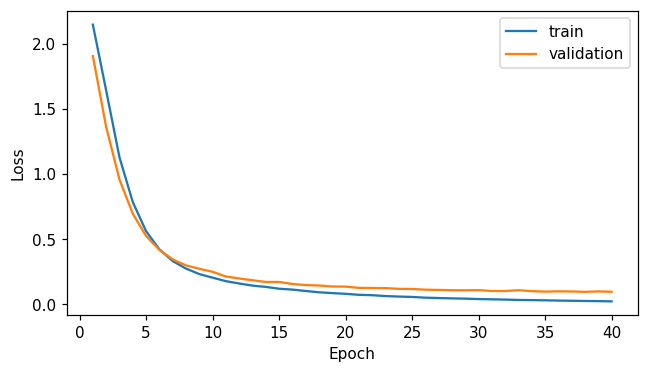

{'accuracy': 0.9777777777777777, 'macro_f1': 0.9775582516887008, 'nll': 0.08965887663512946}


In [7]:
print(inspect.getsource(SpikingMLP))
model = SpikingMLP(steps=12)
history = Trainer(model, nn.CrossEntropyLoss(), TrainConfig(epochs=EPOCHS)).fit(
    train_loader, validation_loader
)
plot_history(history, output / "loss.png")
logits, labels = predict(model, test_loader)
scores = classification_scores(logits, labels)
print(scores)
assert torch.equal(model(data.test.tensors[0][:4]), model(data.test.tensors[0][:4]))

## Voltage trace

A single neuron's voltage is recorded before its reset. The graph relates its current, threshold crossings and spikes. Repeated steps here simulate accumulation under a fixed image, not measured temporal events.

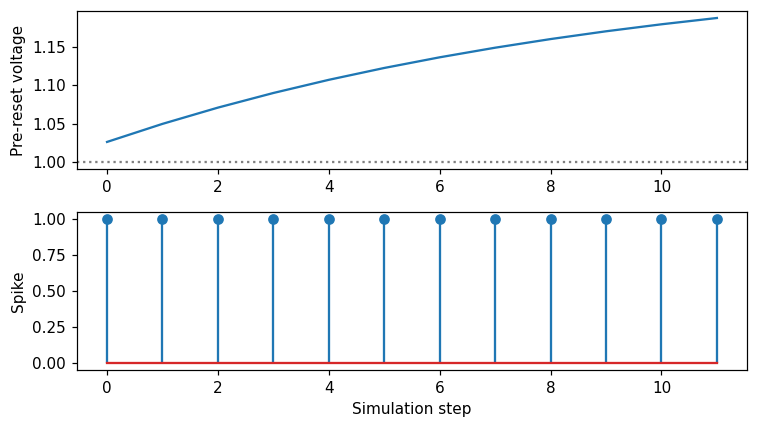

In [9]:
image = data.test.tensors[0][:1]
current = model.input_layer(image.flatten(1)).detach()
membrane = torch.zeros_like(current)
traces, emitted = [], []
for step in range(model.steps):
    membrane = model.decay * membrane + current
    spikes = (membrane > 1).float()
    traces.append(membrane[0].clone())
    emitted.append(spikes[0].clone())
    membrane -= spikes
traces, emitted = torch.stack(traces), torch.stack(emitted)
neuron = int(emitted.sum(0).argmax())
fig, axes = plt.subplots(2, 1, figsize=(7, 4))
axes[0].plot(traces[:, neuron])
axes[0].axhline(1, color="gray", linestyle=":")
axes[1].stem(emitted[:, neuron])
axes[0].set(ylabel="Pre-reset voltage")
axes[1].set(xlabel="Simulation step", ylabel="Spike")
fig.tight_layout()
fig.savefig(output / "trace.png", dpi=140)
plt.show()
results = {
    "test": scores,
    "simulation_steps": model.steps,
    "encoding": "deterministic_current",
    "readout": "continuous",
}

## Reading the result

The surrogate derivative is a training choice and does not equal the mathematical derivative of the hard threshold. Classification accuracy measures the software model. It does not measure energy savings on neuromorphic hardware.

Recorded run: The recorded 40-epoch model reached 97.78% test accuracy with twelve accumulation steps. The deterministic current encoding made repeated evaluation identical. The computation still ran as an ordinary dense PyTorch simulation on CPU.

In [11]:
result_path = root / "results" / "08_spiking_network.json"
result_path.write_text(json.dumps(results, indent=2, allow_nan=False) + "\n")
print(result_path.relative_to(root))

results/08_spiking_network.json


## Next experiment

Compare current encoding with reproducibly seeded Bernoulli rate encoding. Validate each choice of simulation length and report both classification quality and mean hidden spike count.

## Sources

UniPd Machine Learning for Human Data: uploaded Lab_nn and Labs 1 to 7, plus the [course data folder](https://drive.google.com/drive/folders/14xwb6leBeD3QMZH6wnnIIOi63D1D8xmS). Lab_6. [Surrogate gradient learning](https://arxiv.org/abs/1901.09948).

The implementations here were written for this project. Course notebooks and their saved weights are reference material; they are not redistributed.